In [1]:
import pandas as pd

clients = pd.read_csv("data/client_features.csv")

repayment_features = ["pay_0", "pay_2", "pay_3", "pay_4", "pay_5", "pay_6"]
amount_features = (
    ["limit_bal"]
    + [f"bill_amt{i}" for i in range(1, 7)]
    + [f"pay_amt{i}" for i in range(1, 7)]
)
model_features = repayment_features + amount_features
target = "default_payment_next_month"

training = clients.loc[clients["split_name"].eq("train")]
validation = clients.loc[clients["split_name"].eq("validation")]

X_train, y_train = training[model_features], training[target]
X_val, y_val = validation[model_features], validation[target]

print("Training predictors:", X_train.shape, "| Defaults:", y_train.sum())
print("Validation predictors:", X_val.shape, "| Defaults:", y_val.sum())

Training predictors: (18000, 19) | Defaults: 3982
Validation predictors: (6000, 19) | Defaults: 1327


In [2]:
baseline_probability = y_train.mean()
baseline_val_probabilities = pd.Series(
    baseline_probability,
    index=y_val.index,
    name="baseline_probability",
)

baseline_val_brier = ((baseline_val_probabilities - y_val) ** 2).mean()

print(f"Baseline default probability: {baseline_probability:.2%}")
print(f"Validation Brier score: {baseline_val_brier:.4f}")

Baseline default probability: 22.12%
Validation Brier score: 0.1723


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    ("repayment", OneHotEncoder(handle_unknown="ignore"), repayment_features),
    ("amounts", StandardScaler(), amount_features),
])

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("logistic", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)),
])

logistic_model.fit(X_train, y_train)

print("Outcome classes:", logistic_model.classes_)
print("Solver iterations:", logistic_model.named_steps["logistic"].n_iter_[0])

Outcome classes: [0 1]
Solver iterations: 76


In [4]:
logistic_val_probabilities = pd.Series(
    logistic_model.predict_proba(X_val)[:, 1],
    index=y_val.index,
    name="logistic_probability",
)

logistic_val_brier = ((logistic_val_probabilities - y_val) ** 2).mean()

pd.Series({
    "Baseline": baseline_val_brier,
    "Logistic regression": logistic_val_brier,
}, name="Validation Brier score").round(4)

Baseline               0.1723
Logistic regression    0.1414
Name: Validation Brier score, dtype: float64

In [5]:
from sklearn.metrics import average_precision_score, roc_auc_score

validation_ranking = pd.DataFrame(
    {
        "ROC AUC": [
            roc_auc_score(y_val, baseline_val_probabilities),
            roc_auc_score(y_val, logistic_val_probabilities),
        ],
        "Average precision": [
            average_precision_score(y_val, baseline_val_probabilities),
            average_precision_score(y_val, logistic_val_probabilities),
        ],
    },
    index=["Baseline", "Logistic regression"],
)

validation_ranking.round(4)

,ROC AUC,Average precision
Baseline,0.5000,0.2212
Logistic regression,0.7536,0.5106


In [6]:
validation_scores = pd.DataFrame({
    "predicted_probability": logistic_val_probabilities,
    "defaulted": y_val,
})

validation_scores["probability_band"] = pd.cut(
    validation_scores["predicted_probability"],
    bins=[i / 10 for i in range(11)],
    labels=[f"{10 * i}–{10 * (i + 1)}%" for i in range(10)],
    include_lowest=True,
)

validation_calibration = validation_scores.groupby(
    "probability_band", observed=True
).agg(
    client_count=("defaulted", "size"),
    mean_predicted_probability=("predicted_probability", "mean"),
    observed_default_rate=("defaulted", "mean"),
)

validation_calibration.style.format({
    "mean_predicted_probability": "{:.2%}",
    "observed_default_rate": "{:.2%}",
})

,client_count,mean_predicted_probability,observed_default_rate
probability_band,,,
0–10%,897,7.52%,6.02%
10–20%,3452,13.82%,14.92%
20–30%,564,24.17%,27.13%
30–40%,305,33.66%,35.74%
40–50%,114,44.98%,56.14%
50–60%,104,55.57%,51.92%
60–70%,256,64.07%,62.50%
70–80%,125,75.02%,62.40%
80–90%,179,84.28%,76.54%


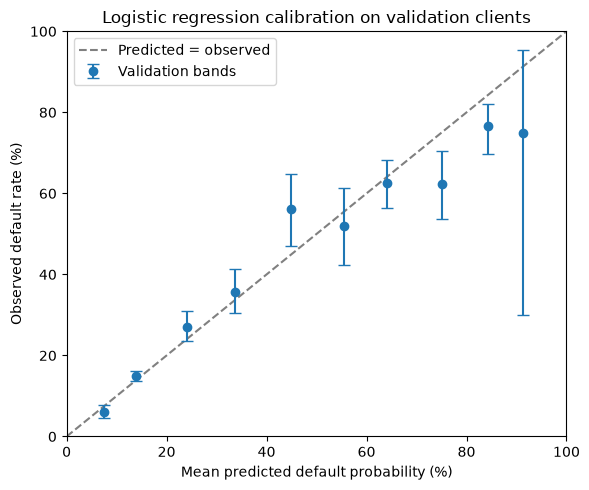

In [7]:
import matplotlib.pyplot as plt
from scipy.stats import binomtest

default_counts = validation_scores.groupby(
    "probability_band", observed=True
)["defaulted"].sum()

calibration = validation_calibration.assign(default_count=default_counts)
intervals = [
    binomtest(int(band.default_count), int(band.client_count))
    .proportion_ci(confidence_level=0.95, method="wilson")
    for band in calibration.itertuples()
]

observed_pct = 100 * calibration["observed_default_rate"]
lower_pct = [100 * interval.low for interval in intervals]
upper_pct = [100 * interval.high for interval in intervals]

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 100], [0, 100], "--", color="gray", label="Predicted = observed")
ax.errorbar(
    100 * calibration["mean_predicted_probability"],
    observed_pct,
    yerr=[observed_pct - lower_pct, upper_pct - observed_pct],
    fmt="o",
    capsize=4,
    label="Validation bands",
)
ax.set(
    xlim=(0, 100),
    ylim=(0, 100),
    xlabel="Mean predicted default probability (%)",
    ylabel="Observed default rate (%)",
    title="Logistic regression calibration on validation clients",
)
ax.legend()
fig.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import log_loss

validation_metrics = validation_ranking.copy()
validation_metrics["Brier score"] = [
    baseline_val_brier,
    logistic_val_brier,
]
validation_metrics["Log loss"] = [
    log_loss(y_val, baseline_val_probabilities),
    log_loss(y_val, logistic_val_probabilities),
]

validation_metrics.round(4)

,ROC AUC,Average precision,Brier score,Log loss
Baseline,0.5000,0.2212,0.1723,0.5284
Logistic regression,0.7536,0.5106,0.1414,0.4483


In [9]:
import numpy as np

feature_names = logistic_model.named_steps["preprocessing"].get_feature_names_out()
coefficients = pd.Series(
    logistic_model.named_steps["logistic"].coef_[0],
    index=feature_names,
)

prefix = "repayment__pay_0_"
september_coefficients = coefficients[
    coefficients.index.str.startswith(prefix)
].copy()
september_coefficients.index = (
    september_coefficients.index.str.replace(prefix, "", regex=False)
    .astype(float)
    .astype(int)
)
september_coefficients = september_coefficients.sort_index()

difference = september_coefficients - september_coefficients.loc[-1]

pd.DataFrame({
    "Log-odds difference vs paid on time": difference,
    "Odds ratio vs paid on time": np.exp(difference),
}).rename_axis("September status code").round(3)

,Log-odds difference vs paid on time,Odds ratio vs paid on time
September status code,,
-2,-0.530,0.589
-1,0.000,1.000
0,-0.781,0.458
1,0.329,1.389
2,1.558,4.748
3,1.595,4.930
4,1.540,4.666
5,0.543,1.721
6,0.783,2.187


In [10]:
review_capacity = int(0.20 * len(logistic_val_probabilities))
ranked_val_scores = logistic_val_probabilities.sort_values(ascending=False)
review_cutoff = ranked_val_scores.iloc[review_capacity]
validation_flagged = logistic_val_probabilities.gt(review_cutoff)

print(f"Review capacity: {review_capacity:,}")
print(f"Review scores above: {review_cutoff:.6%}")
print(f"Clients flagged: {validation_flagged.sum():,}")
print(f"Clients at the cutoff: {logistic_val_probabilities.eq(review_cutoff).sum():,}")

Review capacity: 1,200
Review scores above: 27.011590%
Clients flagged: 1,200
Clients at the cutoff: 1


In [11]:
validation_confusion = pd.crosstab(
    y_val,
    validation_flagged,
    rownames=["Actual outcome"],
    colnames=["Review decision"],
).rename(
    index={0: "No default", 1: "Default"},
    columns={False: "Not flagged", True: "Flagged"},
)

display(validation_confusion)

defaults_caught = validation_confusion.loc["Default", "Flagged"]
print(f"Precision: {defaults_caught / validation_flagged.sum():.2%}")
print(f"Recall: {defaults_caught / y_val.sum():.2%}")

Review decision,Not flagged,Flagged
Actual outcome,,
No default,4119,554
Default,681,646


Precision: 53.83%
Recall: 48.68%


In [12]:
test = clients.loc[clients["split_name"].eq("test")]
X_test, y_test = test[model_features], test[target]

baseline_test_probabilities = pd.Series(baseline_probability, index=y_test.index)
logistic_test_probabilities = pd.Series(
    logistic_model.predict_proba(X_test)[:, 1],
    index=y_test.index,
)

test_metrics = {}
for model_name, probabilities in {
    "Baseline": baseline_test_probabilities,
    "Logistic regression": logistic_test_probabilities,
}.items():
    test_metrics[model_name] = {
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "Average precision": average_precision_score(y_test, probabilities),
        "Brier score": ((probabilities - y_test) ** 2).mean(),
        "Log loss": log_loss(y_test, probabilities),
    }

test_metrics = pd.DataFrame.from_dict(test_metrics, orient="index")
test_metrics.round(4)

,ROC AUC,Average precision,Brier score,Log loss
Baseline,0.5000,0.2212,0.1723,0.5284
Logistic regression,0.7719,0.5527,0.1354,0.4350


In [13]:
test_flagged = logistic_test_probabilities.gt(review_cutoff)

test_confusion = pd.crosstab(
    y_test,
    test_flagged,
    rownames=["Actual outcome"],
    colnames=["Review decision"],
).rename(
    index={0: "No default", 1: "Default"},
    columns={False: "Not flagged", True: "Flagged"},
)

display(test_confusion)

test_defaults_caught = test_confusion.loc["Default", "Flagged"]
print(f"Clients flagged: {test_flagged.sum():,} ({test_flagged.mean():.2%})")
print(f"Precision: {test_defaults_caught / test_flagged.sum():.2%}")
print(f"Recall: {test_defaults_caught / y_test.sum():.2%}")

Review decision,Not flagged,Flagged
Actual outcome,,
No default,4101,572
Default,632,695


Clients flagged: 1,267 (21.12%)
Precision: 54.85%
Recall: 52.37%


In [14]:
test_scores = pd.DataFrame({
    "client_id": test["client_id"],
    "predicted_probability": logistic_test_probabilities,
    "defaulted": y_test,
})

test_scores["probability_band"] = pd.cut(
    test_scores["predicted_probability"],
    bins=[i / 10 for i in range(11)],
    labels=validation_scores["probability_band"].cat.categories,
    include_lowest=True,
)

test_calibration = test_scores.groupby("probability_band", observed=False).agg(
    client_count=("defaulted", "size"),
    default_count=("defaulted", "sum"),
    mean_predicted_probability=("predicted_probability", "mean"),
    observed_default_rate=("defaulted", "mean"),
)

test_calibration.style.format({
    "mean_predicted_probability": "{:.2%}",
    "observed_default_rate": "{:.2%}",
}, na_rep="—")

,client_count,default_count,mean_predicted_probability,observed_default_rate
probability_band,,,,
0–10%,907,51,7.46%,5.62%
10–20%,3405,471,13.80%,13.83%
20–30%,564,149,24.56%,26.42%
30–40%,318,123,33.75%,38.68%
40–50%,108,57,45.45%,52.78%
50–60%,117,71,55.27%,60.68%
60–70%,268,166,63.69%,61.94%
70–80%,131,94,75.07%,71.76%
80–90%,180,143,84.24%,79.44%


In [15]:
ranked_test_scores = test_scores.sort_values(
    ["predicted_probability", "client_id"],
    ascending=[False, True],
)

queue_rows = []
for review_share in (0.10, 0.20):
    queue = ranked_test_scores.head(int(review_share * len(test_scores)))
    reviewed = len(queue)
    defaults_captured = queue["defaulted"].sum()

    queue_rows.append({
        "review_share": review_share,
        "clients_reviewed": reviewed,
        "defaults_captured": defaults_captured,
        "nondefaults_reviewed": reviewed - defaults_captured,
        "capture_rate": defaults_captured / y_test.sum(),
        "lift": (defaults_captured / reviewed) / y_test.mean(),
    })

test_queue_summary = pd.DataFrame(queue_rows)
test_queue_summary.style.format({
    "review_share": "{:.0%}",
    "capture_rate": "{:.2%}",
    "lift": "{:.2f}×",
})

,review_share,clients_reviewed,defaults_captured,nondefaults_reviewed,capture_rate,lift
0,10%,600,415,185,31.27%,3.13×
1,20%,1200,673,527,50.72%,2.54×


In [16]:
from pathlib import Path

export_dir = Path("data/model_evaluation")
export_dir.mkdir(parents=True, exist_ok=True)

model_name = "Logistic regression"
exports = {
    "test_scores": ranked_test_scores.assign(
        model=model_name,
        queue_rank=range(1, len(ranked_test_scores) + 1),
        review_cutoff=review_cutoff,
        flagged_at_cutoff=test_flagged,
    ),
    "test_metrics": test_metrics.rename_axis("model").reset_index(),
    "test_calibration": test_calibration.reset_index().assign(model=model_name),
    "test_queue_summary": test_queue_summary.assign(model=model_name),
}

for name, table in exports.items():
    path = export_dir / f"{name}.csv"
    table.assign(population="test", model_version="v1").to_csv(path, index=False)
    print(f"Saved {len(table):,} rows to {path}")

Saved 6,000 rows to data\model_evaluation\test_scores.csv
Saved 2 rows to data\model_evaluation\test_metrics.csv
Saved 10 rows to data\model_evaluation\test_calibration.csv
Saved 2 rows to data\model_evaluation\test_queue_summary.csv


In [17]:
import sys
from importlib.metadata import version

print(f"Python {sys.version.split()[0]}")
for package in ("pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "ipykernel"):
    print(f"{package}=={version(package)}")

Python 3.14.6
pandas==3.0.3
numpy==2.4.6
scipy==1.18.0
scikit-learn==1.9.0
matplotlib==3.11.0
ipykernel==6.31.0
